# Proactive Bitrate Adaptation for Cloud Gaming over 5G — Full Analysis

This notebook reproduces **every table and figure** in the report from the raw LUMOS 5G data, in one place:

| Report item | Section below |
|---|---|
| Fig. 4 — throughput trace (title corrected: Run 1 is a **driving** trace) | 2 |
| Table II, Fig. 6 — LSTM at 20 vs 50 epochs | 5–6 |
| Fig. 7 — predicted vs actual | 7 |
| Table III, Fig. 8 — LSTM vs SMA vs Last Value | 8 |
| Table IV — walking vs driving | 9 |
| Table V — bitrate tier distribution | 10 |
| Table VI, Fig. 9 — bitrate switching frequency | 11 |
| Fig. 5 / Fig. 10 — handover analysis | 12 |
| Robustness across random seeds | 13 |

All figures are saved to `figures/`, all tables to `results/`. A fixed random seed makes the LSTM results repeatable.

## 1. Setup and data loading

In [1]:
import os, copy, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

SEED = 42
EPOCHS = 50
SNAPSHOT_EPOCH = 20
RUN_SEED_CHECK = True
EXTRA_SEEDS = [1, 2, 3]

torch.set_num_threads(2)  # small LSTM: 2 threads trains ~5x faster than the default on this laptop
os.makedirs('figures', exist_ok=True)
os.makedirs('results', exist_ok=True)

df = pd.read_csv('Lumos5G-v1.0/Lumos5G-v1.0.csv')
print("Shape:", df.shape)
print("\nMobility modes:", df['mobility_mode'].value_counts().to_dict())
print("Runs per (mode, direction):", df.groupby(['mobility_mode', 'trajectory_direction'])['run_num'].nunique().to_dict())

Shape: (68118, 19)

Mobility modes: {'walking': 56935, 'driving': 11183}
Runs per (mode, direction): {('driving', 'CW'): 46, ('walking', 'ACW'): 38, ('walking', 'CW'): 34}


## 2. Fig. 4 — Raw 5G throughput trace (corrected title)

`run_num` restarts for every mobility mode and direction, so Run 1 has to be selected together with its mode.
In this dataset, `run_num == 1` exists **only** for driving (clockwise), so the original title "Walking Scenario" was wrong.

Run 1 rows: 230 | modes in run_num == 1: ['driving']


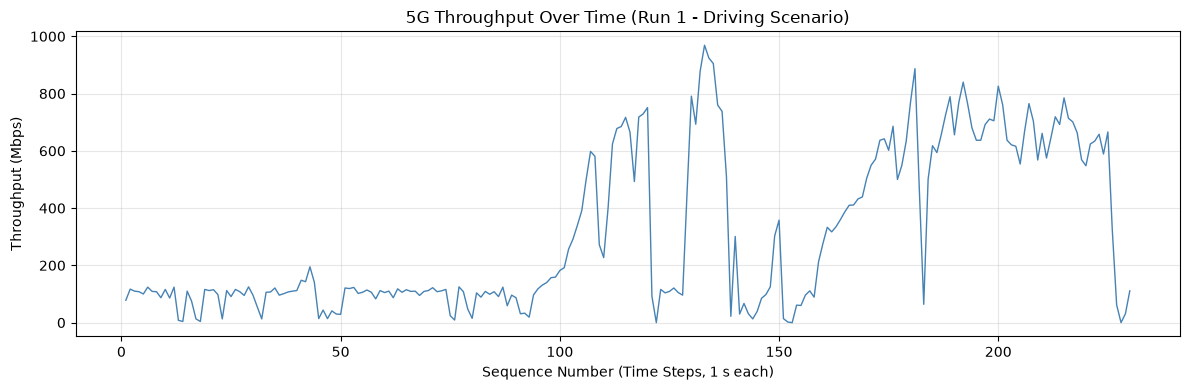

In [2]:
run1 = df[(df['run_num'] == 1) & (df['mobility_mode'] == 'driving')]
print("Run 1 rows:", len(run1), "| modes in run_num == 1:", df[df['run_num'] == 1]['mobility_mode'].unique().tolist())

plt.figure(figsize=(12, 4))
plt.plot(run1['seq_num'], run1['Throughput'], color='steelblue', linewidth=1)
plt.title('5G Throughput Over Time (Run 1 - Driving Scenario)')
plt.xlabel('Sequence Number (Time Steps, 1 s each)')
plt.ylabel('Throughput (Mbps)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('figures/fig4_throughput_run1_driving.png', dpi=150)
plt.show()

## 3. Preprocessing, sequences and chronological split

In [3]:
features = ['Throughput', 'movingSpeed', 'lte_rsrp', 'lte_rsrq', 'nr_ssRsrp', 'nr_ssRsrq', 'nr_ssSinr']

print("Missing 5G NR values: %.1f%% of rows (device on LTE)" % (df['nr_ssRsrp'].isna().mean() * 100))
print("lte_rssnr rows holding the 'unavailable' placeholder (2,147,483,647):",
      int((df['lte_rssnr'] > 1e9).sum()), "of", int(df['lte_rssnr'].notna().sum()), "-> column not used")

df_clean = df[features].fillna(0)
scaler = MinMaxScaler()
df_scaled = scaler.fit_transform(df_clean)

def create_sequences(data, sequence_length=10):
    X, y = [], []
    for i in range(len(data) - sequence_length):
        X.append(data[i:i+sequence_length])
        y.append(data[i+sequence_length][0])
    return np.array(X), np.array(y)

sequence_length = 10
X, y = create_sequences(df_scaled, sequence_length)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, shuffle=False
)
print("\nSequences:", len(X), "| Train:", len(X_train), "| Test:", len(X_test))

X_train_t = torch.FloatTensor(X_train)
X_test_t = torch.FloatTensor(X_test)
y_train_t = torch.FloatTensor(y_train).unsqueeze(1)
y_test_t = torch.FloatTensor(y_test).unsqueeze(1)
y_test_np = y_test_t.numpy().flatten()

throughput_min = df['Throughput'].min()
throughput_max = df['Throughput'].max()

Missing 5G NR values: 23.7% of rows (device on LTE)
lte_rssnr rows holding the 'unavailable' placeholder (2,147,483,647): 65137 of 65137 -> column not used



Sequences: 68108 | Train: 54486 | Test: 13622


## 4. LSTM model and training function

In [4]:
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=2, output_size=1):
        super(LSTMModel, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers,
                            batch_first=True, dropout=0.2)
        self.fc1 = nn.Linear(hidden_size, 32)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(32, output_size)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.fc1(out[:, -1, :])
        out = self.relu(out)
        out = self.fc2(out)
        return out

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def predict(model):
    model.eval()
    with torch.no_grad():
        return model(X_test_t).numpy().flatten()

def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'MSE': mse, 'RMSE': np.sqrt(mse), 'MAE': mean_absolute_error(y_true, y_pred)}

def train_model(seed, epochs, snapshot_epoch=None, verbose=True):
    set_seed(seed)
    model = LSTMModel(X_train.shape[2])
    train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=256, shuffle=False)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    losses, snapshot = [], None
    for epoch in range(epochs):
        model.train()
        epoch_loss = 0
        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(X_batch), y_batch)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
        losses.append(epoch_loss / len(train_loader))
        if verbose:
            print(f"Epoch {epoch+1}/{epochs} - Loss: {losses[-1]:.6f}")
        if epoch + 1 == snapshot_epoch:
            snapshot = copy.deepcopy(model)
    return model, snapshot, losses

print(LSTMModel(X_train.shape[2]))

LSTMModel(
  (lstm): LSTM(7, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc1): Linear(in_features=64, out_features=32, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=32, out_features=1, bias=True)
)


## 5. Training (one run, snapshot at the 20th epoch) — Table II

In [5]:
model, model_20, train_losses = train_model(SEED, EPOCHS, snapshot_epoch=SNAPSHOT_EPOCH)
torch.save(model_20.state_dict(), 'results/lstm_model_20ep.pth')
torch.save(model.state_dict(), 'results/lstm_model_50ep.pth')

y_pred_20 = predict(model_20)
y_pred_np = predict(model)

table2 = pd.DataFrame([metrics(y_test_np, y_pred_20), metrics(y_test_np, y_pred_np)],
                      index=[f'LSTM {SNAPSHOT_EPOCH} Epochs', f'LSTM {EPOCHS} Epochs'])
table2.to_csv('results/table2_epochs.csv')
print("=" * 50)
print("TABLE II - LSTM PERFORMANCE AT 20 AND 50 EPOCHS")
print("=" * 50)
print(table2.round(6).to_string())
print("\nMSE reduction from %d to %d epochs: %.1f%%"
      % (SNAPSHOT_EPOCH, EPOCHS, (1 - table2['MSE'].iloc[1] / table2['MSE'].iloc[0]) * 100))

Epoch 1/50 - Loss: 0.029039


Epoch 2/50 - Loss: 0.012236


Epoch 3/50 - Loss: 0.009705


Epoch 4/50 - Loss: 0.009262


Epoch 5/50 - Loss: 0.009094


...

Epoch 47/50 - Loss: 0.008236


Epoch 48/50 - Loss: 0.008252


Epoch 49/50 - Loss: 0.008210


Epoch 50/50 - Loss: 0.008208


TABLE II - LSTM PERFORMANCE AT 20 AND 50 EPOCHS
                     MSE      RMSE       MAE
LSTM 20 Epochs  0.007931  0.089056  0.059972
LSTM 50 Epochs  0.007575  0.087036  0.055966

MSE reduction from 20 to 50 epochs: 4.5%


## 6. Fig. 6 — Training loss

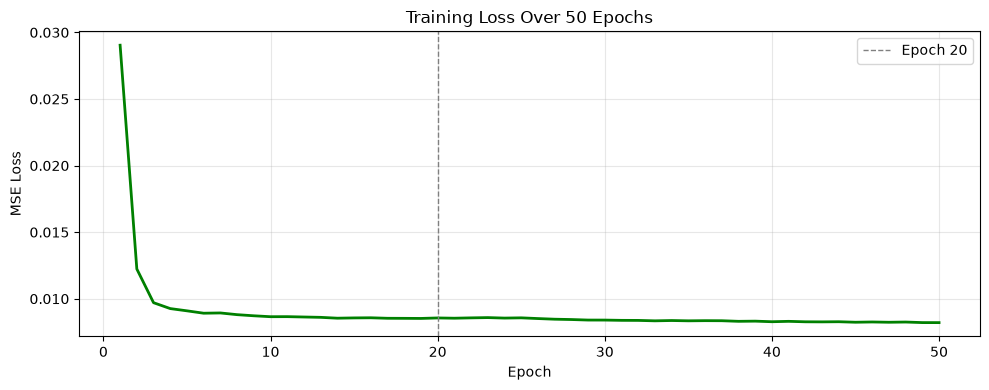

In [6]:
plt.figure(figsize=(10, 4))
plt.plot(range(1, len(train_losses) + 1), train_losses, color='green', linewidth=2)
plt.axvline(SNAPSHOT_EPOCH, color='gray', linestyle='--', linewidth=1, label=f'Epoch {SNAPSHOT_EPOCH}')
plt.title(f'Training Loss Over {EPOCHS} Epochs')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('figures/fig6_training_loss.png', dpi=150)
plt.show()

## 7. Fig. 7 — Predicted vs actual throughput (50-epoch model)

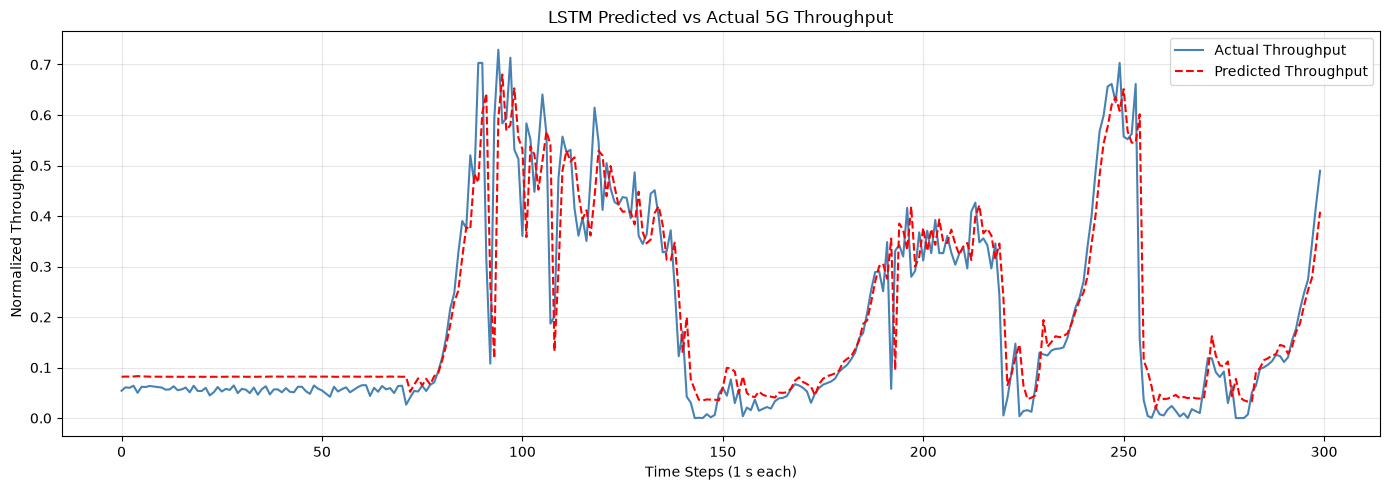

In [7]:
plt.figure(figsize=(14, 5))
plt.plot(y_test_np[:300], label='Actual Throughput', color='steelblue', linewidth=1.5)
plt.plot(y_pred_np[:300], label='Predicted Throughput', color='red', linewidth=1.5, linestyle='--')
plt.title('LSTM Predicted vs Actual 5G Throughput')
plt.xlabel('Time Steps (1 s each)')
plt.ylabel('Normalized Throughput')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('figures/fig7_predicted_vs_actual.png', dpi=150)
plt.show()

## 8. Baselines — Table III and Fig. 8

* **SMA**: mean of the last 10 throughput values in the input window.
* **Last Value**: repeats the most recent throughput (what a purely reactive controller assumes).

Both baselines are deterministic, so they match the report exactly. The LSTM row uses the 50-epoch model.

TABLE III - LSTM VS BASELINE PREDICTORS
                   MSE      RMSE       MAE
LSTM (Ours)   0.007575  0.087036  0.055966
SMA Baseline  0.019840  0.140856  0.090254
Last Value    0.008210  0.090611  0.049969

LSTM MSE reduction vs SMA:        61.8%
LSTM MSE reduction vs Last Value: 7.7%


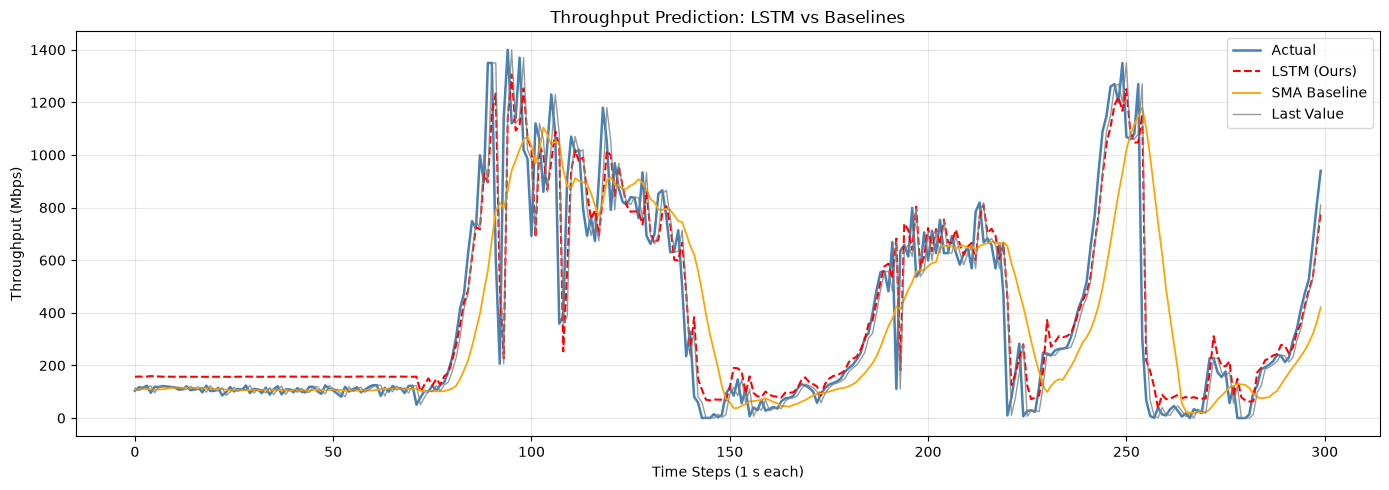

In [8]:
sma_pred = X_test_t[:, :, 0].mean(dim=1).numpy()
last_pred = X_test_t[:, -1, 0].numpy()

table3 = pd.DataFrame([metrics(y_test_np, y_pred_np), metrics(y_test_np, sma_pred), metrics(y_test_np, last_pred)],
                      index=['LSTM (Ours)', 'SMA Baseline', 'Last Value'])
table3.to_csv('results/table3_baselines.csv')
print("=" * 50)
print("TABLE III - LSTM VS BASELINE PREDICTORS")
print("=" * 50)
print(table3.round(6).to_string())
print("\nLSTM MSE reduction vs SMA:        %.1f%%" % ((1 - table3.loc['LSTM (Ours)', 'MSE'] / table3.loc['SMA Baseline', 'MSE']) * 100))
print("LSTM MSE reduction vs Last Value: %.1f%%" % ((1 - table3.loc['LSTM (Ours)', 'MSE'] / table3.loc['Last Value', 'MSE']) * 100))

to_mbps = lambda v: v * (throughput_max - throughput_min) + throughput_min
y_test_actual = to_mbps(y_test_np)
y_pred_actual = to_mbps(y_pred_np)
sma_actual = to_mbps(sma_pred)
last_actual = to_mbps(last_pred)

plt.figure(figsize=(14, 5))
plt.plot(y_test_actual[:300], label='Actual', color='steelblue', linewidth=1.8)
plt.plot(y_pred_actual[:300], label='LSTM (Ours)', color='red', linewidth=1.5, linestyle='--')
plt.plot(sma_actual[:300], label='SMA Baseline', color='orange', linewidth=1.3)
plt.plot(last_actual[:300], label='Last Value', color='gray', linewidth=1, alpha=0.8)
plt.title('Throughput Prediction: LSTM vs Baselines')
plt.xlabel('Time Steps (1 s each)')
plt.ylabel('Throughput (Mbps)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('figures/fig8_baseline_comparison.png', dpi=150)
plt.show()

## 9. Mobility-specific analysis — Table IV

In [9]:
# target of sequence i is row i + sequence_length, so the test targets are the last len(X_test) rows
test_mode = df['mobility_mode'].values[sequence_length:][len(X_train):]

rows = {}
for mode in ['walking', 'driving']:
    mask = test_mode == mode
    rows[mode.capitalize()] = {**metrics(y_test_np[mask], y_pred_np[mask]), 'Samples': int(mask.sum())}
rows['Overall'] = {**metrics(y_test_np, y_pred_np), 'Samples': len(y_test_np)}
table4 = pd.DataFrame(rows).T
table4['Samples'] = table4['Samples'].astype(int)
table4.to_csv('results/table4_mobility.csv')
print("=" * 50)
print("TABLE IV - PERFORMANCE BY MOBILITY MODE")
print("=" * 50)
print(table4.round(6).to_string())
print("\nDriving MSE is %.1f%% lower than walking" % ((1 - table4.loc['Driving', 'MSE'] / table4.loc['Walking', 'MSE']) * 100))

TABLE IV - PERFORMANCE BY MOBILITY MODE
              MSE      RMSE       MAE  Samples
Walking  0.007993  0.089402  0.057765    11938
Driving  0.004616  0.067942  0.043214     1684
Overall  0.007575  0.087036  0.055966    13622

Driving MSE is 42.2% lower than walking


## 10. Bitrate adaptation — Table V

In [10]:
TIERS = ['360p', '480p', '720p', '1080p', '1440p']
TIER_INFO = {'1440p': ('6,000 Kbps', '> 500 Mbps'), '1080p': ('3,000 Kbps', '200-500 Mbps'),
             '720p': ('2,000 Kbps', '100-200 Mbps'), '480p': ('1,000 Kbps', '50-100 Mbps'),
             '360p': ('500 Kbps', '< 50 Mbps')}

def select_tier(predicted_mbps):
    # same thresholds as select_bitrate() in the original notebook; returns 0 (360p) .. 4 (1440p)
    return np.select([predicted_mbps >= 500, predicted_mbps >= 200, predicted_mbps >= 100, predicted_mbps >= 50],
                     [4, 3, 2, 1], 0)

lstm_tiers = select_tier(y_pred_actual)
counts = np.bincount(lstm_tiers, minlength=5)
table5 = pd.DataFrame({
    'Bitrate': [TIER_INFO[t][0] for t in TIERS[::-1]],
    'Throughput Range': [TIER_INFO[t][1] for t in TIERS[::-1]],
    'Samples': counts[::-1],
    'Percentage': np.round(counts[::-1] / counts.sum() * 100, 1),
}, index=TIERS[::-1])
table5.to_csv('results/table5_tiers.csv')
print("=" * 50)
print("TABLE V - BITRATE TIER DISTRIBUTION (LSTM)")
print("=" * 50)
print(table5.to_string())
print("\n720p or higher: %.1f%% of predictions" % (counts[2:].sum() / counts.sum() * 100))

TABLE V - BITRATE TIER DISTRIBUTION (LSTM)
          Bitrate Throughput Range  Samples  Percentage
1440p  6,000 Kbps       > 500 Mbps     5452        40.0
1080p  3,000 Kbps     200-500 Mbps     2147        15.8
720p   2,000 Kbps     100-200 Mbps     4315        31.7
480p   1,000 Kbps      50-100 Mbps     1682        12.3
360p     500 Kbps        < 50 Mbps       26         0.2

720p or higher: 87.5% of predictions


## 11. Bitrate switching frequency — Table VI and Fig. 9

Switching frequency = share of consecutive time steps where the selected quality tier changes.

TABLE VI - BITRATE SWITCHING FREQUENCY
              Switching Frequency (%)
LSTM (Ours)                     18.62
SMA Baseline                     8.61
Last Value                      27.86
Actual                          27.87

LSTM switches 33.2% less often than actual-throughput (reactive) adaptation


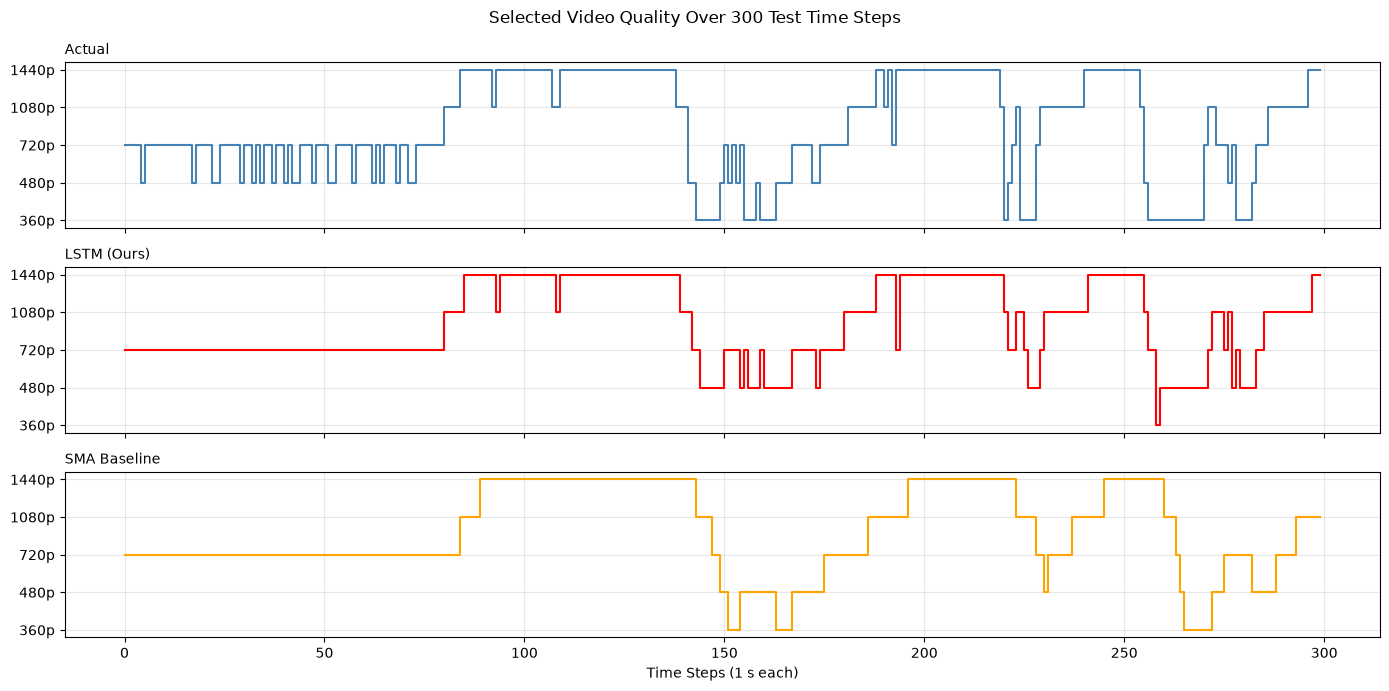

In [11]:
# Mbps values come from float32 tensors (as in the original notebook); throughput exactly at a
# threshold can round just below it, which is why 'Actual' is 27.87% here and 27.52% in exact arithmetic.
tier_sets = {'LSTM (Ours)': lstm_tiers, 'SMA Baseline': select_tier(sma_actual),
             'Last Value': select_tier(last_actual), 'Actual': select_tier(y_test_actual)}
table6 = pd.DataFrame({'Switching Frequency (%)': {k: np.mean(t[1:] != t[:-1]) * 100 for k, t in tier_sets.items()}})
table6.to_csv('results/table6_switching.csv')
print("=" * 50)
print("TABLE VI - BITRATE SWITCHING FREQUENCY")
print("=" * 50)
print(table6.round(2).to_string())
reduction = (1 - table6.loc['LSTM (Ours)'].iloc[0] / table6.loc['Actual'].iloc[0]) * 100
print("\nLSTM switches %.1f%% less often than actual-throughput (reactive) adaptation" % reduction)

fig, axes = plt.subplots(3, 1, figsize=(14, 7), sharex=True)
for ax, (name, color) in zip(axes, [('Actual', 'steelblue'), ('LSTM (Ours)', 'red'), ('SMA Baseline', 'orange')]):
    ax.step(range(300), tier_sets[name][:300], where='post', color=color, linewidth=1.5)
    ax.set_yticks(range(5))
    ax.set_yticklabels(TIERS)
    ax.set_title(name, fontsize=10, loc='left')
    ax.grid(True, alpha=0.3)
axes[-1].set_xlabel('Time Steps (1 s each)')
fig.suptitle('Selected Video Quality Over 300 Test Time Steps')
plt.tight_layout()
plt.savefig('figures/fig9_bitrate_selection.png', dpi=150)
plt.show()

## 12. Handover analysis — Fig. 5 / Fig. 10

A handover is a change of `tower_id` between consecutive rows (row 0 is not counted).
Throughput **before** = mean of the 5 seconds before the change; **after** = mean of the handover second and the 5 seconds after it.

HANDOVER ANALYSIS
Handover events                    1370
Percent of time steps              2.01
Walking events                      881
Driving events                      489
Events inside a single run         1298
Mean throughput before (Mbps)    386.99
Mean throughput after (Mbps)     301.75
Mean drop (Mbps)                  85.23


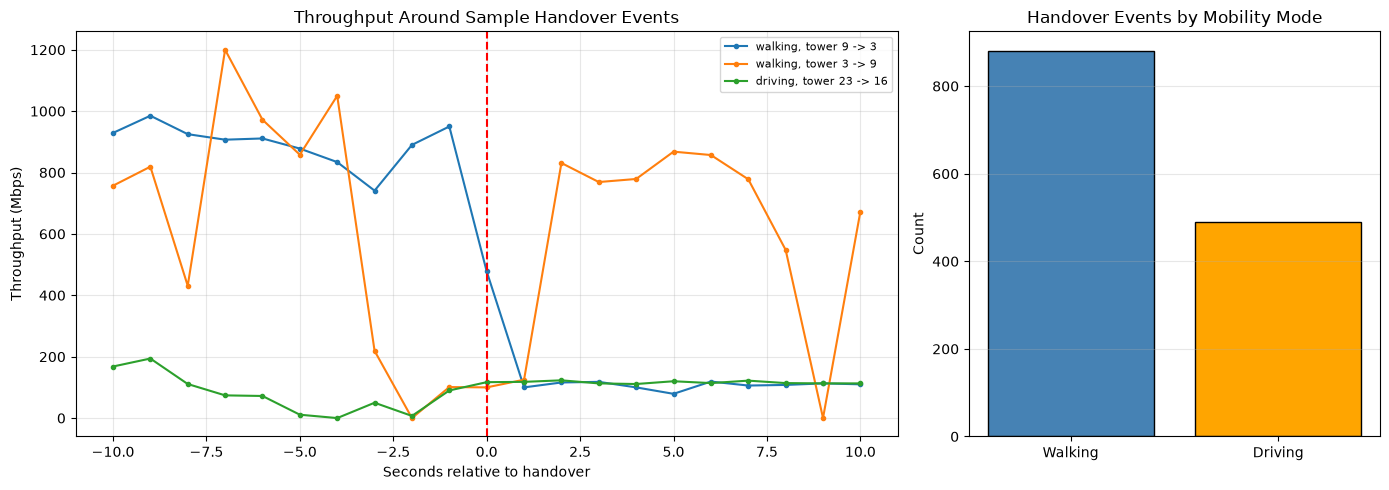

In [12]:
WINDOW = 5
tower = df['tower_id']
is_ho = (tower != tower.shift()) & (df.index > 0)
ho_idx = np.where(is_ho)[0]

same_run = ((df['run_num'] == df['run_num'].shift()) & (df['mobility_mode'] == df['mobility_mode'].shift())
            & (df['trajectory_direction'] == df['trajectory_direction'].shift()))
within_run_idx = np.where(is_ho & same_run)[0]

thr = df['Throughput'].values.astype(float)
before = np.mean([thr[max(0, i - WINDOW):i].mean() for i in ho_idx])
after = np.mean([thr[i:i + WINDOW + 1].mean() for i in ho_idx])
by_mode = df['mobility_mode'].iloc[ho_idx].value_counts()

handover = pd.Series({
    'Handover events': len(ho_idx),
    'Percent of time steps': round(len(ho_idx) / len(df) * 100, 2),
    'Walking events': int(by_mode.get('walking', 0)),
    'Driving events': int(by_mode.get('driving', 0)),
    'Events inside a single run': len(within_run_idx),
    'Mean throughput before (Mbps)': round(before, 2),
    'Mean throughput after (Mbps)': round(after, 2),
    'Mean drop (Mbps)': round(before - after, 2),
}, dtype=object)
handover.to_csv('results/handover_summary.csv', header=['Value'])
print("=" * 50)
print("HANDOVER ANALYSIS")
print("=" * 50)
print(handover.to_string())

# three evenly spaced sample events that have +/-10 s of data inside the same run
span = 10
valid = [i for i in within_run_idx
         if i - span >= 0 and i + span < len(df) and same_run.iloc[i - span + 1:i + span + 1].all()]
samples = [valid[int(len(valid) * q)] for q in (0.25, 0.5, 0.75)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [2, 1]})
for i in samples:
    axes[0].plot(range(-span, span + 1), thr[i - span:i + span + 1], marker='o', markersize=3, linewidth=1.5,
                 label=f"{df['mobility_mode'].iloc[i]}, tower {tower.iloc[i-1]} -> {tower.iloc[i]}")
axes[0].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title('Throughput Around Sample Handover Events')
axes[0].set_xlabel('Seconds relative to handover')
axes[0].set_ylabel('Throughput (Mbps)')
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)

axes[1].bar(['Walking', 'Driving'], [handover['Walking events'], handover['Driving events']],
            color=['steelblue', 'orange'], edgecolor='black')
axes[1].set_title('Handover Events by Mobility Mode')
axes[1].set_ylabel('Count')
axes[1].grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('figures/fig5_fig10_handover_analysis.png', dpi=150)
plt.show()

## 13. Robustness across random seeds

LSTM weights start from random values, so each training run lands on slightly different numbers.
This trains the same model with three more seeds to show how much the results move between runs.

In [13]:
if RUN_SEED_CHECK:
    seed_rows = {f'seed {SEED}': {**metrics(y_test_np, y_pred_np),
                                  'Switching (%)': table6.loc['LSTM (Ours)'].iloc[0],
                                  '720p+ (%)': counts[2:].sum() / counts.sum() * 100}}
    for s in EXTRA_SEEDS:
        m, _, _ = train_model(s, EPOCHS, verbose=False)
        p = predict(m)
        t = select_tier(to_mbps(p))
        seed_rows[f'seed {s}'] = {**metrics(y_test_np, p),
                                  'Switching (%)': np.mean(t[1:] != t[:-1]) * 100,
                                  '720p+ (%)': np.mean(t >= 2) * 100}
        print(f"seed {s} done")
    seeds = pd.DataFrame(seed_rows).T
    seeds.loc['mean'] = seeds.mean()
    seeds.loc['std'] = seeds.iloc[:-1].std()
    seeds.to_csv('results/seed_robustness.csv')
    print("=" * 60)
    print(f"LSTM ({EPOCHS} epochs) ACROSS {len(EXTRA_SEEDS) + 1} RANDOM SEEDS")
    print("=" * 60)
    print(seeds.round(6).to_string())
    print("\nFor reference - SMA MSE: %.6f, Last Value MSE: %.6f"
          % (table3.loc['SMA Baseline', 'MSE'], table3.loc['Last Value', 'MSE']))

seed 1 done


seed 2 done


seed 3 done


LSTM (50 epochs) ACROSS 4 RANDOM SEEDS
              MSE      RMSE       MAE  Switching (%)  720p+ (%)
seed 42  0.007575  0.087036  0.055966      18.618310  87.461459
seed 1   0.007513  0.086677  0.054359      18.721092  87.109088
seed 2   0.007431  0.086200  0.052304      18.647676  86.822787
seed 3   0.007537  0.086816  0.053116      18.596285  86.477757
mean     0.007514  0.086682  0.053936      18.645841  86.967773
std      0.000061  0.000354  0.001596       0.054406   0.418264

For reference - SMA MSE: 0.019840, Last Value MSE: 0.008210


## 14. Summary — numbers from this notebook

In [14]:
summary = pd.Series({
    f'LSTM MSE ({EPOCHS} ep)': round(table3.loc['LSTM (Ours)', 'MSE'], 6),
    f'LSTM RMSE ({EPOCHS} ep)': round(table3.loc['LSTM (Ours)', 'RMSE'], 6),
    f'LSTM MAE ({EPOCHS} ep)': round(table3.loc['LSTM (Ours)', 'MAE'], 6),
    'MAE in Mbps': round(table3.loc['LSTM (Ours)', 'MAE'] * (throughput_max - throughput_min), 1),
    'RMSE in Mbps': round(table3.loc['LSTM (Ours)', 'RMSE'] * (throughput_max - throughput_min), 1),
    'MSE reduction vs SMA (%)': round((1 - table3.loc['LSTM (Ours)', 'MSE'] / table3.loc['SMA Baseline', 'MSE']) * 100, 1),
    'MSE reduction vs Last Value (%)': round((1 - table3.loc['LSTM (Ours)', 'MSE'] / table3.loc['Last Value', 'MSE']) * 100, 1),
    'Driving MSE lower than walking (%)': round((1 - table4.loc['Driving', 'MSE'] / table4.loc['Walking', 'MSE']) * 100, 1),
    '720p or higher (%)': round(counts[2:].sum() / counts.sum() * 100, 1),
    'LSTM switching (%)': round(table6.loc['LSTM (Ours)'].iloc[0], 2),
    'Actual switching (%)': round(table6.loc['Actual'].iloc[0], 2),
    'Handover events': handover['Handover events'],
    'Handover drop (Mbps)': handover['Mean drop (Mbps)'],
}, dtype=object)
summary.to_csv('results/summary.csv', header=['Value'])
print(summary.to_string())

LSTM MSE (50 ep)                      0.007575
LSTM RMSE (50 ep)                     0.087036
LSTM MAE (50 ep)                      0.055966
MAE in Mbps                              107.5
RMSE in Mbps                             167.1
MSE reduction vs SMA (%)                  61.8
MSE reduction vs Last Value (%)            7.7
Driving MSE lower than walking (%)        42.2
720p or higher (%)                        87.5
LSTM switching (%)                       18.62
Actual switching (%)                     27.87
Handover events                           1370
Handover drop (Mbps)                     85.23
